# 02 - Pitch archetypes

**Goal:** group pitches into archetypes so park effects can be measured on groups with enough data, instead of on individual pitchers.

An archetype is a pitch group (four-seam, sinker, slider, ...) crossed with percentile tiers **within that pitch group** for arm slot, velocity, and induced vertical break. Tier counts are set in `src/archetypes.py` and are easy to change. The default is 2 x 2 x 2 = 8 archetypes per pitch group. More tiers make archetypes more specific but leave fewer balls in play per park, so check the cell sizes in notebook 03 before adding tiers.

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
from src.config import PROCESSED, INTERIM
from src.data import load_seasons, add_park, ANALYSIS_COLS
from src.archetypes import add_shape_features, add_archetypes

In [2]:
df = add_park(load_seasons(columns=ANALYSIS_COLS))
df = add_shape_features(df)
df = add_archetypes(df)
df = df.dropna(subset=["archetype"])
print(f"{len(df):,} pitches, {df['archetype'].nunique()} archetypes")

Arm slot source: Statcast arm_angle
3,528,630 pitches, 32 archetypes


## Sanity check: movement direction

Arm-side run is positive for both hands after the sign flip. Sinkers and changeups should show positive values for both RHP and LHP, and sliders, sweepers, and cutters should be negative. If not, the sign convention in `add_shape_features` needs fixing before anything else.

In [3]:
df.groupby(["pitch_group", "p_throws"])["arm_side_in"].mean().round(1).unstack()

p_throws,L,R
pitch_group,,
Changeup,14.1,14.3
Curveball,-7.7,-9.1
Cutter,-1.9,-2.4
Four-seam,7.9,7.6
Sinker,15.2,14.9
Slider,-4.5,-4.5
Splitter,9.2,11.1
Sweeper,-13.7,-13.8


## Archetype sizes

In [4]:
sizes = df["archetype"].value_counts()
sizes.describe()

count        32.000000
mean     110269.687500
std       89071.778578
min       18157.000000
25%       57376.750000
50%       76899.500000
75%      131935.250000
max      391580.000000
Name: count, dtype: float64

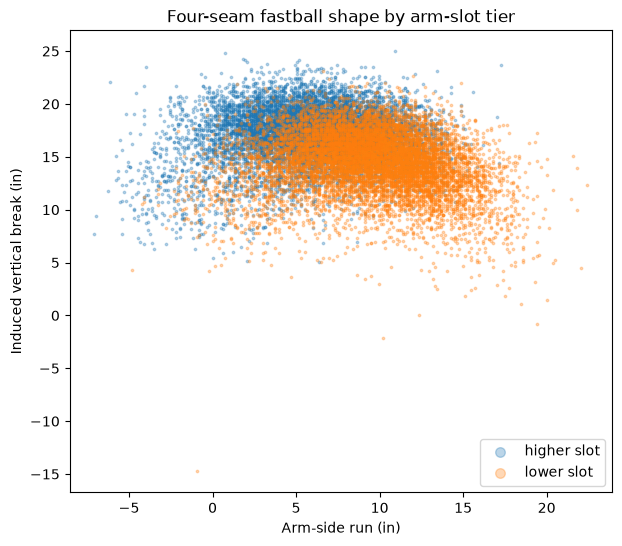

In [5]:
ff = df[df["pitch_group"] == "Four-seam"]
ff = ff.sample(min(20000, len(ff)), random_state=0)

fig, ax = plt.subplots(figsize=(7, 6))
for tier, g in ff.groupby("slot_tier"):
    ax.scatter(g["arm_side_in"], g["ivb_in"], s=3, alpha=0.3, label=f"{tier} slot")
ax.set_xlabel("Arm-side run (in)")
ax.set_ylabel("Induced vertical break (in)")
ax.set_title("Four-seam fastball shape by arm-slot tier")
ax.legend(markerscale=4)
plt.show()

## Save cut points and outputs

The cut points document exactly what "high slot" or "faster" means for each pitch group. Put them on the methodology slide.

In [6]:
cut = (df.groupby("pitch_group")[["release_speed", "ivb_in", "slot_value"]]
         .quantile([1/3, 0.5, 2/3]).round(1))
cut.to_csv(PROCESSED / "archetype_cutpoints.csv")
cut

release_speed  ivb_in  slot_value
pitch_group                                            
Changeup    0.333333           84.4     3.1        32.5
            0.500000           85.9     5.2        37.4
            0.666667           87.3     7.3        42.1
Curveball   0.333333           78.5   -12.6        39.8
            0.500000           80.1   -10.3        44.3
            0.666667           81.6    -8.0        48.6
Cutter      0.333333           88.1     6.5        35.4
            0.500000           89.3     7.9        40.0
            0.666667           90.6     9.5        44.4
Four-seam   0.333333           93.3    14.9        36.0
            0.500000           94.3    16.1        40.9
            0.666667           95.4    17.3        45.6
Sinker      0.333333           92.5     6.2        29.5
            0.500000           93.7     8.2        34.7
            0.666667           94.9    10.0        39.8
Slider      0.333333           84.8     0.0        35.5
            0.500000           86.1     1.8        40.2
            0.666667           87.3     3.5        44.5
Splitter    0.333333           84.9     1.2        36.3
            0.500000           86.4     3.0        39.4
            0.666667           87.9     4.9        43.1
Sweeper     0.333333           81.2    -1.2        27.3
            0.500000           82.4     0.7        32.0
            0.666667           83.6     2.6        36.8

In [7]:
INTERIM.mkdir(parents=True, exist_ok=True)
df.to_parquet(INTERIM / "pitches_archetyped.parquet", index=False)
sizes.rename_axis("archetype").reset_index(name="pitches").to_csv(PROCESSED / "archetype_sizes.csv", index=False)

## Commit

```
git add notebooks/02_archetypes.ipynb data/processed/archetype_cutpoints.csv data/processed/archetype_sizes.csv
git commit -m "define pitch archetypes and save cut points"
git push
```